# LSTM (Long Short-Term Memory) — Temelden Uygulamaya
### PyTorch ve Keras ile satır satır açıklamalı

**İçerik**
1. Neden LSTM? RNN'in sorunu
2. LSTM algoritması: hücre durumu ve 3 kapı
3. Elle küçük bir sayısal örnek (NumPy)
4. Veri hazırlama (gürültülü sinüs dalgası — RNN notebook'uyla aynı)
5. **PyTorch** ile LSTM — elle yazılmış hücre, `nn.LSTM` ile birebir doğrulama, eğitim
6. **Keras** ile LSTM — `layers.LSTM`
7. Karşılaştırma, RNN ile farklar ve GRU

**Görev:** Bir sinüs dalgasının son 20 değerine bakıp **bir sonraki** değeri tahmin etmek.

## 1. Neden LSTM? RNN'in sorunu

Basit RNN'de hafıza her adımda **tamamen yeniden yazılır**:
$$h_t = \tanh(W_{xh}\,x_t + W_{hh}\,h_{t-1} + b)$$

Geri yayılımda gradyan her adımda $W_{hh}$ ve $\tanh'$ ile **çarpılır**. 50 adım sonra:
- $0.9^{50} \approx 0.005$ → gradyan **kaybolur**: ağ uzak geçmişi öğrenemez.
- $1.1^{50} \approx 117$ → gradyan **patlar**.

**LSTM'in fikri (Hochreiter & Schmidhuber, 1997):** Hafızayı çarpma zincirinden kurtarmak.
Ayrı bir **hücre durumu** $c_t$ tutulur ve bu hücre **toplama** ile güncellenir. Neyin silineceğine, neyin yazılacağına ve neyin okunacağına da öğrenilen **kapılar** karar verir.

> **Benzetme:** $c_t$ bir **taşıma bandıdır**. Bilgi bant üzerinde neredeyse hiç değişmeden ilerler.
> Kapılar bandın yanındaki işçilerdir: biri eski eşyaları atar (**unut**), biri yenilerini koyar (**girdi**), biri bant üzerinden dışarıya ne gösterileceğini seçer (**çıkış**).

## 2. LSTM algoritması

Her zaman adımında girdi olarak $x_t$, önceki gizli durum $h_{t-1}$ ve önceki hücre durumu $c_{t-1}$ gelir.

### 2.1 Üç kapı ve bir aday
Hepsi aynı girdiyi görür: $[x_t,\ h_{t-1}]$.

| Ad | Formül | Aktivasyon | Görevi |
|---|---|---|---|
| **Unut kapısı** $f_t$ | $\sigma(W_f x_t + U_f h_{t-1} + b_f)$ | sigmoid → $[0,1]$ | Eski hafızanın ne kadarı **silinsin**? (0 = hepsini sil, 1 = hepsini tut) |
| **Girdi kapısı** $i_t$ | $\sigma(W_i x_t + U_i h_{t-1} + b_i)$ | sigmoid → $[0,1]$ | Yeni bilginin ne kadarı **yazılsın**? |
| **Aday** $g_t$ (ya da $\tilde{c}_t$) | $\tanh(W_g x_t + U_g h_{t-1} + b_g)$ | tanh → $[-1,1]$ | Yazılacak **yeni bilgi** nedir? |
| **Çıkış kapısı** $o_t$ | $\sigma(W_o x_t + U_o h_{t-1} + b_o)$ | sigmoid → $[0,1]$ | Hafızanın ne kadarı **dışarı gösterilsin**? |

### 2.2 Hafızanın güncellenmesi (LSTM'in kalbi)
$$c_t = f_t \odot c_{t-1} \;+\; i_t \odot g_t$$
$$h_t = o_t \odot \tanh(c_t)$$

($\odot$: eleman eleman çarpım)

- **1. terim** $f_t \odot c_{t-1}$: eski hafızanın tutulan kısmı.
- **2. terim** $i_t \odot g_t$: eklenen yeni bilgi.
- $h_t$: hücre durumunun filtrelenmiş hâli. Bir sonraki adıma ve çıktı katmanına giden kısım budur.

### 2.3 Neden gradyan kaybolmuyor?
$$\frac{\partial c_t}{\partial c_{t-1}} = f_t$$
Hücre durumu boyunca gradyan, $W_{hh}$ ve $\tanh'$ ile değil yalnızca **unut kapısıyla** çarpılır.
Ağ uzun süre hatırlaması gereken bir şeyi gördüğünde $f_t \approx 1$ yapmayı **öğrenir**. Böylece gradyan onlarca adım boyunca neredeyse hiç küçülmeden akar.

### 2.4 Akış diyagramı
```
            c_{t-1} ──(×f_t)──────(+)────────────────► c_t
                                   ▲                  │
                                (i_t × g_t)          tanh
                                   ▲                  │
  [x_t, h_{t-1}] ──► f_t, i_t, g_t, o_t               (×o_t) ──► h_t
```

### 2.5 Parametre sayısı
4 blok (f, i, g, o) vardır ve her birinin $W$, $U$ ve $b$ parametreleri bulunur. Bu yüzden LSTM, aynı boyuttaki bir RNN'in **yaklaşık 4 katı** parametreye sahiptir:
$$4 \times (H \cdot F + H \cdot H + H)$$

## 3. Elle küçük bir sayısal örnek

Gizli boyut 1, girdi dizisi $[0.5,\ 0.8]$. Her kapı için ağırlıkları elle seçiyoruz.
Unut kapısının bias'ını **yüksek** (+1) seçtik; bu, "varsayılan olarak hatırla" demek. Pratikte de sık kullanılan bir başlangıç ayarıdır.

In [1]:
import numpy as np                       # Sayısal hesaplama kütüphanesi

def sigmoid(z):                          # Sigmoid: sayıyı 0-1 arasına sıkıştırır (kapılar için)
    return 1 / (1 + np.exp(-z))

# Her kapı için (W: girdi ağırlığı, U: gizli durum ağırlığı, b: bias) — hepsi skaler (H=1)
W_f, U_f, b_f = 0.5, 0.5, 1.0            # Unut kapısı (bias +1 → varsayılan olarak hatırla)
W_i, U_i, b_i = 1.0, 0.5, 0.0            # Girdi kapısı
W_g, U_g, b_g = 1.0, 0.5, 0.0            # Aday (yeni bilgi)
W_o, U_o, b_o = 1.0, 0.5, 0.0            # Çıkış kapısı

x_dizi = [0.5, 0.8]                      # 2 adımlık girdi dizisi
h, c = 0.0, 0.0                          # h_0 ve c_0: başlangıçta hafıza boş

for t, x_t in enumerate(x_dizi, start=1):
    f = sigmoid(W_f * x_t + U_f * h + b_f)   # Unut kapısı: eski c'nin ne kadarı tutulsun
    i = sigmoid(W_i * x_t + U_i * h + b_i)   # Girdi kapısı: yeni bilginin ne kadarı yazılsın
    g = np.tanh(W_g * x_t + U_g * h + b_g)   # Aday: yazılacak yeni bilgi
    o = sigmoid(W_o * x_t + U_o * h + b_o)   # Çıkış kapısı: c'nin ne kadarı dışarı gösterilsin
    c = f * c + i * g                        # LSTM'in kalbi: hücre durumu TOPLAMA ile güncellenir
    h = o * np.tanh(c)                       # Gizli durum: hücre durumunun filtrelenmiş hâli
    print(f"t={t}: f={f:.3f}  i={i:.3f}  g={g:.3f}  o={o:.3f}  →  c_{t}={c:.4f}  h_{t}={h:.4f}")

t=1: f=0.777  i=0.622  g=0.462  o=0.622  →  c_1=0.2876  h_1=0.1743
t=2: f=0.816  i=0.708  g=0.710  o=0.708  →  c_2=0.7375  h_2=0.4445


**Yorum:** $t=2$'de $c_2 = f_2 \cdot c_1 + i_2 \cdot g_2$. Unut kapısı yüksek olduğu için ($f_2 \approx 0.8$), ilk adımın bilgisinin büyük kısmı korunuyor ve yeni bilgi bunun **üzerine ekleniyor**. Basit RNN'de ise $h$ her adımda tanh içinde yeniden hesaplanıyordu.

## 4. Veri hazırlama

RNN notebook'uyla **birebir aynı** veri: gürültülü sinüs ve 20 adımlık kayan pencere.
Girdi şekli `(N, 20, 1)` = (örnek sayısı, zaman adımı, özellik sayısı), hedef şekli `(N, 1)`.

In [2]:
import matplotlib.pyplot as plt          # Grafik çizmek için

np.random.seed(42)                       # Gürültü her çalıştırmada aynı olsun

t = np.linspace(0, 100, 2000)            # 0 ile 100 arasında eşit aralıklı 2000 zaman noktası
seri = np.sin(t) + 0.05 * np.random.randn(len(t))  # Sinüs + biraz gürültü

PENCERE = 20                             # Model geçmişteki 20 adıma bakacak (T)

X, y = [], []
for i in range(len(seri) - PENCERE):     # Pencereyi seri boyunca birer adım kaydır
    X.append(seri[i:i + PENCERE])        # Girdi: 20 ardışık değer
    y.append(seri[i + PENCERE])          # Hedef: hemen sonraki değer

X = np.array(X, dtype="float32")[..., None]  # (N, 20, 1)
y = np.array(y, dtype="float32")[:, None]    # (N, 1)

bolme = int(0.8 * len(X))                # %80 eğitim / %20 test
X_egitim_np, y_egitim_np = X[:bolme], y[:bolme]
X_test_np,   y_test_np   = X[bolme:], y[bolme:]

print("X şekli:", X.shape, "| y şekli:", y.shape)
print("Eğitim:", X_egitim_np.shape[0], "örnek | Test:", X_test_np.shape[0], "örnek")

X şekli: (1980, 20, 1) | y şekli: (1980, 1)
Eğitim: 1584 örnek | Test: 396 örnek


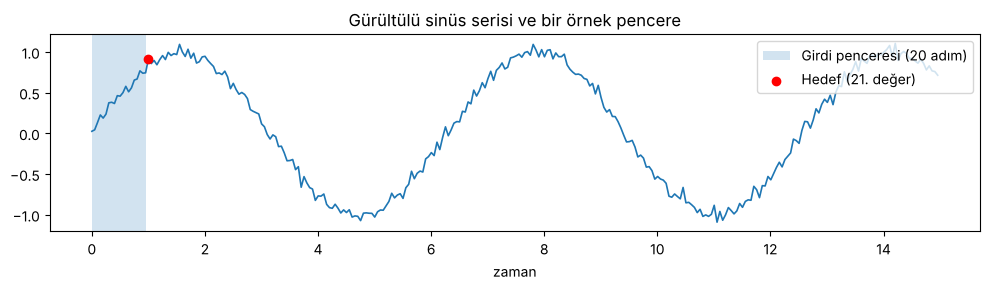

In [3]:
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(t[:300], seri[:300], lw=1.2)                                    # Serinin ilk 300 noktası
ax.axvspan(t[0], t[PENCERE - 1], alpha=0.2, label="Girdi penceresi (20 adım)")
ax.scatter(t[PENCERE], seri[PENCERE], color="red", zorder=3, label="Hedef (21. değer)")
ax.set_title("Gürültülü sinüs serisi ve bir örnek pencere")
ax.set_xlabel("zaman"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

## 5. PyTorch ile LSTM

### 5.1 Önce temel: LSTM hücresini **elle** yazalım
Dört kapıyı ayrı ayrı hesaplamak yerine, bir verimlilik hilesi kullanıyoruz: tek bir `Linear` katmanı çıktısını `4H` boyutunda üretiyor, sonra bu çıktıyı 4 parçaya bölüyoruz. `nn.LSTM` da içeride tam olarak bunu yapar. Kapıların sırası **i, f, g, o**.

In [4]:
import torch                             # PyTorch çekirdeği
import torch.nn as nn                    # Hazır katmanlar
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)                    # Tekrarlanabilirlik

class ElleLSTM(nn.Module):
    def __init__(self, girdi_boyutu, gizli_boyut):
        super().__init__()                                         # nn.Module kurucusu (zorunlu)
        self.H = gizli_boyut                                       # Gizli boyut
        self.W_x = nn.Linear(girdi_boyutu, 4 * gizli_boyut)        # x_t → 4 kapının hepsi birden (W_i,W_f,W_g,W_o)
        self.W_h = nn.Linear(gizli_boyut, 4 * gizli_boyut)         # h_{t-1} → 4 kapının hepsi birden (U_i,U_f,U_g,U_o)

    def forward(self, x):                                          # x: (B, T, F)
        B, T, _ = x.shape
        h = torch.zeros(B, self.H)                                 # h_0 = 0
        c = torch.zeros(B, self.H)                                 # c_0 = 0 (hücre durumu)
        cikislar = []
        for t in range(T):                                         # Zamanda adım adım ilerle
            z = self.W_x(x[:, t, :]) + self.W_h(h)                 # Tüm kapıların ham değeri: (B, 4H)
            i, f, g, o = z.chunk(4, dim=1)                         # 4 eşit parçaya böl → her biri (B, H)
            i = torch.sigmoid(i)                                   # Girdi kapısı   ∈ [0,1]
            f = torch.sigmoid(f)                                   # Unut kapısı    ∈ [0,1]
            g = torch.tanh(g)                                      # Aday bilgi     ∈ [-1,1]
            o = torch.sigmoid(o)                                   # Çıkış kapısı   ∈ [0,1]
            c = f * c + i * g                                      # Hücre durumu: eskinin bir kısmı + yeninin bir kısmı
            h = o * torch.tanh(c)                                  # Gizli durum: hücrenin filtrelenmiş hâli
            cikislar.append(h)                                     # Her adımın h_t'sini sakla
        return torch.stack(cikislar, dim=1), (h, c)                # nn.LSTM ile aynı dönüş biçimi

### 5.2 Elle yazdığımız hücre gerçekten `nn.LSTM` ile aynı mı?
`nn.LSTM`'in ağırlıklarını bizim hücremize kopyalayıp aynı girdiyi veriyoruz. Çıktılar aynıysa algoritmayı doğru anlamışız demektir.

In [5]:
hazir = nn.LSTM(input_size=1, hidden_size=32, batch_first=True)  # PyTorch'un hazır LSTM'i
elle  = ElleLSTM(girdi_boyutu=1, gizli_boyut=32)                  # Bizim hücremiz

with torch.no_grad():                                             # Ağırlık kopyalarken türev takibi gereksiz
    elle.W_x.weight.copy_(hazir.weight_ih_l0)                     # (4H, F): girdi ağırlıkları
    elle.W_x.bias.copy_(hazir.bias_ih_l0)                         # (4H,): girdi bias'ı
    elle.W_h.weight.copy_(hazir.weight_hh_l0)                     # (4H, H): gizli durum ağırlıkları
    elle.W_h.bias.copy_(hazir.bias_hh_l0)                         # (4H,): gizli durum bias'ı

ornek = torch.tensor(X_test_np[:4])                               # 4 test örneği
with torch.no_grad():
    cik_hazir, (h_hazir, c_hazir) = hazir(ornek)                  # Hazır LSTM'in çıktısı
    cik_elle,  (h_elle,  c_elle)  = elle(ornek)                   # Bizim çıktımız

print("Çıkış şekli :", tuple(cik_hazir.shape))                    # (4, 20, 32)
print("En büyük fark (tüm adımlar):", (cik_hazir - cik_elle).abs().max().item())
print("En büyük fark (son c)      :", (c_hazir[0] - c_elle).abs().max().item())
print("Aynı mı?", torch.allclose(cik_hazir, cik_elle, atol=1e-6))

Çıkış şekli : (4, 20, 32)
En büyük fark (tüm adımlar): 7.450580596923828e-08
En büyük fark (son c)      : 5.960464477539063e-08
Aynı mı? True


### 5.3 Veriyi tensöre çevirme ve DataLoader

In [6]:
X_egitim = torch.tensor(X_egitim_np)     # NumPy → PyTorch tensörü
y_egitim = torch.tensor(y_egitim_np)
X_test   = torch.tensor(X_test_np)
y_test   = torch.tensor(y_test_np)

egitim_yukleyici = DataLoader(
    TensorDataset(X_egitim, y_egitim),   # (girdi, hedef) çiftleri
    batch_size=64,                       # Her adımda 64 örnek
    shuffle=True)                        # Her epoch'ta karıştır

### 5.4 Asıl model: hazır `nn.LSTM` katmanı
RNN modelinden **tek fark**: `nn.RNN` yerine `nn.LSTM` kullanılması ve dönüş değerinin `(h, c)` ikilisi olması.

In [7]:
class LSTMModel(nn.Module):
    def __init__(self, girdi_boyutu=1, gizli_boyut=32, cikti_boyutu=1):
        super().__init__()
        self.lstm = nn.LSTM(                # Hazır LSTM katmanı
            input_size=girdi_boyutu,        # Her adımdaki özellik sayısı (1)
            hidden_size=gizli_boyut,        # Gizli/hücre durumu boyutu H = 32
            num_layers=1,                   # Tek katman
            batch_first=True)               # Girdi şekli (B, T, F)
        self.fc = nn.Linear(gizli_boyut, cikti_boyutu)  # Son h_t → tahmin

    def forward(self, x):                   # x: (B, 20, 1)
        cikislar, (h_son, c_son) = self.lstm(x)  # cikislar: (B,20,32); h_son, c_son: (1,B,32)
        son_adim = cikislar[:, -1, :]       # Son adımın gizli durumu: (B, 32)  (= h_son[0])
        return self.fc(son_adim)            # (B, 32) → (B, 1)

model = LSTMModel()
print(model)
print("Parametre sayısı:", sum(p.numel() for p in model.parameters()))
print("  LSTM katmanı:", sum(p.numel() for p in model.lstm.parameters()),
      "= 4 × (32·1 + 32·32 + 32 + 32)  ← PyTorch iki bias tutar")

LSTMModel(
  (lstm): LSTM(1, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=1, bias=True)
)
Parametre sayısı: 4513
  LSTM katmanı: 4480 = 4 × (32·1 + 32·32 + 32 + 32)  ← PyTorch iki bias tutar


### 5.5 Kayıp fonksiyonu, optimizer ve eğitim döngüsü
Döngü RNN ile **tamamen aynı**: `zero_grad → ileri → kayıp → backward → kırpma → step`.

In [8]:
kayip_fn = nn.MSELoss()                     # Ortalama kare hata
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)  # Adam optimizer

EPOCH = 20
pt_kayiplar = []
for epoch in range(EPOCH):
    model.train()                           # Eğitim modu
    toplam_kayip = 0.0
    for xb, yb in egitim_yukleyici:         # Her mini-batch için:
        optimizer.zero_grad()               # 1. Önceki gradyanları sıfırla
        tahmin = model(xb)                  # 2. İleri yayılım
        kayip = kayip_fn(tahmin, yb)        # 3. Hata
        kayip.backward()                    # 4. BPTT: gradyanlar hücre durumu üzerinden de akar
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)  # 5. Gradyan kırpma
        optimizer.step()                    # 6. Ağırlıkları güncelle
        toplam_kayip += kayip.item() * len(xb)
    ort = toplam_kayip / len(X_egitim)
    pt_kayiplar.append(ort)
    print(f"Epoch {epoch + 1:2d}/{EPOCH} | eğitim MSE: {ort:.5f}")

Epoch  1/20 | eğitim MSE: 0.44944
Epoch  2/20 | eğitim MSE: 0.22795
Epoch  3/20 | eğitim MSE: 0.06848
Epoch  4/20 | eğitim MSE: 0.03608


Epoch  5/20 | eğitim MSE: 0.01523
Epoch  6/20 | eğitim MSE: 0.00535
Epoch  7/20 | eğitim MSE: 0.00402
Epoch  8/20 | eğitim MSE: 0.00369


Epoch  9/20 | eğitim MSE: 0.00358
Epoch 10/20 | eğitim MSE: 0.00353
Epoch 11/20 | eğitim MSE: 0.00349
Epoch 12/20 | eğitim MSE: 0.00345


Epoch 13/20 | eğitim MSE: 0.00330
Epoch 14/20 | eğitim MSE: 0.00337
Epoch 15/20 | eğitim MSE: 0.00323
Epoch 16/20 | eğitim MSE: 0.00324


Epoch 17/20 | eğitim MSE: 0.00324
Epoch 18/20 | eğitim MSE: 0.00324
Epoch 19/20 | eğitim MSE: 0.00320
Epoch 20/20 | eğitim MSE: 0.00325


### 5.6 Test

In [9]:
model.eval()                                # Değerlendirme modu
with torch.no_grad():                       # Gradyan hesaplama yok
    pt_test_tahmin = model(X_test)
    pt_test_mse = kayip_fn(pt_test_tahmin, y_test).item()
print(f"PyTorch LSTM Test MSE: {pt_test_mse:.5f}\n")

for i in range(5):
    print(f"Gerçek: {y_test[i].item():+.3f}   Tahmin: {pt_test_tahmin[i].item():+.3f}")

PyTorch LSTM Test MSE: 0.00357

Gerçek: -1.016   Tahmin: -0.999
Gerçek: -1.032   Tahmin: -1.000
Gerçek: -0.968   Tahmin: -1.004
Gerçek: -0.880   Tahmin: -0.996
Gerçek: -0.930   Tahmin: -0.970


### 5.7 Kapıların içine bakalım
Eğitilmiş modelin bir test örneği için kapı değerlerini hesaplayıp ortalamalarını çiziyoruz. Bu grafik, LSTM'in her adımda ne kadar unuttuğunu ve ne kadar yazdığını gösterir.

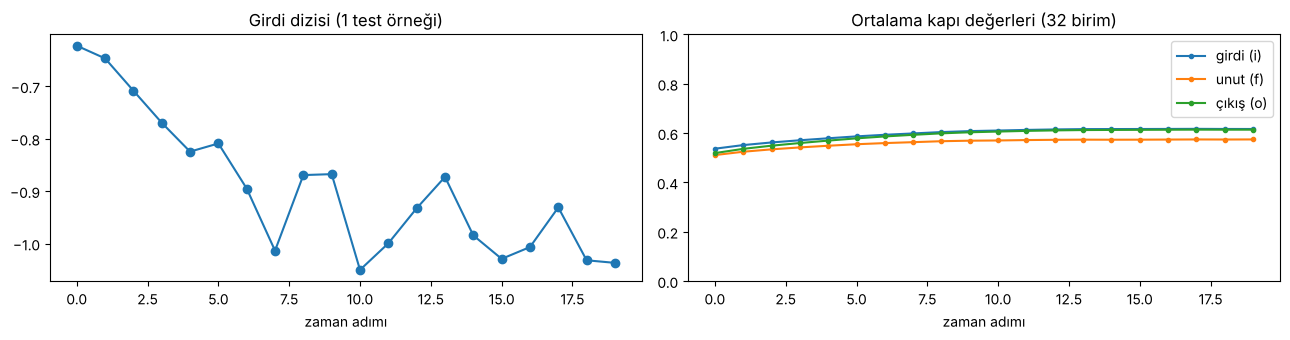

In [10]:
with torch.no_grad():
    Wih, Whh = model.lstm.weight_ih_l0, model.lstm.weight_hh_l0     # Eğitilmiş ağırlıklar
    b = model.lstm.bias_ih_l0 + model.lstm.bias_hh_l0               # İki bias toplanınca tek bias
    x1 = X_test[0]                                                  # Tek bir örnek: (20, 1)
    h = torch.zeros(32); c = torch.zeros(32)
    kayit = {"girdi (i)": [], "unut (f)": [], "çıkış (o)": []}
    for t_ in range(PENCERE):
        z = Wih @ x1[t_] + Whh @ h + b                              # (4H,)
        i, f, g, o = z.chunk(4)
        i, f, g, o = i.sigmoid(), f.sigmoid(), g.tanh(), o.sigmoid()
        c = f * c + i * g; h = o * c.tanh()
        kayit["girdi (i)"].append(i.mean().item())                  # 32 birimin ortalaması
        kayit["unut (f)"].append(f.mean().item())
        kayit["çıkış (o)"].append(o.mean().item())

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].plot(x1[:, 0].numpy(), marker="o"); ax[0].set_title("Girdi dizisi (1 test örneği)")
ax[0].set_xlabel("zaman adımı")
for ad, deger in kayit.items():
    ax[1].plot(deger, marker=".", label=ad)
ax[1].set_ylim(0, 1); ax[1].set_title("Ortalama kapı değerleri (32 birim)")
ax[1].set_xlabel("zaman adımı"); ax[1].legend()
plt.tight_layout(); plt.show()

## 6. Keras ile LSTM

Keras'ta RNN'den LSTM'e geçiş **tek kelime** değişikliği: `SimpleRNN` → `LSTM`.
Keras ayrıca varsayılan olarak `unit_forget_bias=True` kullanır: unut kapısının bias'ı +1 ile başlar ("varsayılan olarak hatırla"). Bölüm 3'teki örnekte yaptığımızın aynısı.

In [11]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # TensorFlow bilgi mesajlarını gizle
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)                    # Tekrarlanabilirlik

keras_model = keras.Sequential([
    keras.Input(shape=(PENCERE, 1)),      # 20 zaman adımı × 1 özellik
    layers.LSTM(
        32,                               # Gizli/hücre durumu boyutu H = 32
        activation="tanh",                # Aday (g) ve çıkıştaki tanh
        recurrent_activation="sigmoid",   # Kapıların (i, f, o) aktivasyonu
        unit_forget_bias=True,            # Unut kapısı bias'ı +1 ile başlasın
        return_sequences=False),          # Sadece son h_t (B, 32)
    layers.Dense(1)                       # Son h_t → tahmin
])
keras_model.summary()                     # LSTM: 4 × (32·1 + 32·32 + 32) = 4352 parametre

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

### 6.1 Derleme ve eğitim

In [12]:
keras_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0),  # Adam + gradyan kırpma
    loss="mse",                           # Ortalama kare hata
    metrics=["mae"])                      # Ortalama mutlak hata da izlensin

gecmis = keras_model.fit(                 # Eğitim döngüsünün tamamı
    X_egitim_np, y_egitim_np,
    epochs=20,
    batch_size=64,
    validation_split=0.1,                 # %10 doğrulama
    shuffle=True,
    verbose=2)                            # Her epoch için tek satır

Epoch 1/20


23/23 - 2s - 69ms/step - loss: 0.1908 - mae: 0.3771 - val_loss: 0.0748 - val_mae: 0.2516


Epoch 2/20


23/23 - 0s - 9ms/step - loss: 0.0526 - mae: 0.2025 - val_loss: 0.0394 - val_mae: 0.1816


Epoch 3/20


...

23/23 - 0s - 8ms/step - loss: 0.0030 - mae: 0.0437 - val_loss: 0.0035 - val_mae: 0.0473


Epoch 19/20


23/23 - 0s - 7ms/step - loss: 0.0030 - mae: 0.0437 - val_loss: 0.0035 - val_mae: 0.0473


Epoch 20/20


23/23 - 0s - 7ms/step - loss: 0.0030 - mae: 0.0436 - val_loss: 0.0035 - val_mae: 0.0473


### 6.2 Test

In [13]:
k_test_mse, k_test_mae = keras_model.evaluate(X_test_np, y_test_np, verbose=0)
print(f"Keras LSTM Test MSE: {k_test_mse:.5f} | Test MAE: {k_test_mae:.5f}\n")

k_test_tahmin = keras_model.predict(X_test_np, verbose=0)
for gercek, tahmin in zip(y_test_np[:5, 0], k_test_tahmin[:5, 0]):
    print(f"Gerçek: {gercek:+.3f}   Tahmin: {tahmin:+.3f}")

Keras LSTM Test MSE: 0.00289 | Test MAE: 0.04234



Gerçek: -1.016   Tahmin: -0.976
Gerçek: -1.032   Tahmin: -0.972
Gerçek: -0.968   Tahmin: -0.970
Gerçek: -0.880   Tahmin: -0.961
Gerçek: -0.930   Tahmin: -0.937


## 7. Karşılaştırma

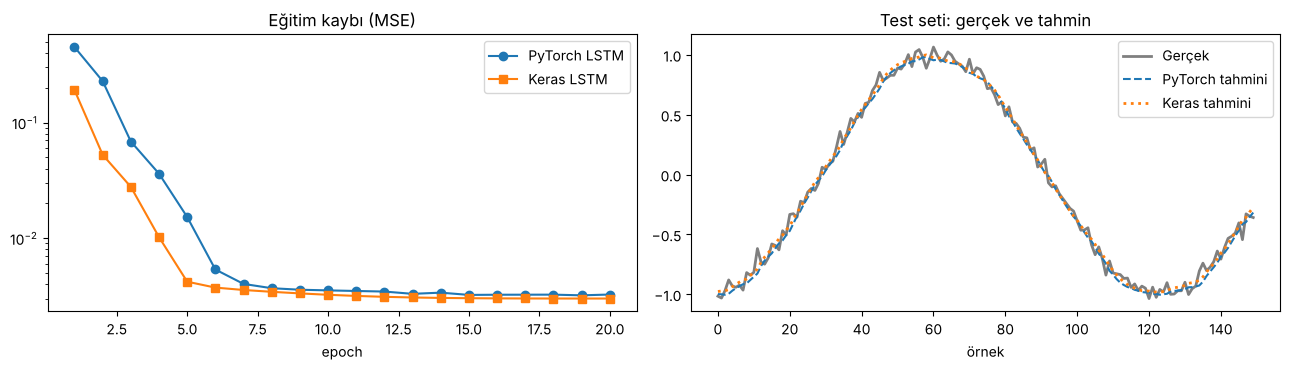

PyTorch LSTM Test MSE: 0.00357
Keras   LSTM Test MSE: 0.00289
Gürültünün kendi varyansı (alt sınır ≈): 0.00250


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))

axes[0].plot(range(1, 21), pt_kayiplar, marker="o", label="PyTorch LSTM")
axes[0].plot(range(1, 21), gecmis.history["loss"], marker="s", label="Keras LSTM")
axes[0].set_yscale("log")
axes[0].set_title("Eğitim kaybı (MSE)"); axes[0].set_xlabel("epoch"); axes[0].legend()

n = 150
axes[1].plot(y_test_np[:n, 0], color="black", lw=2, alpha=0.5, label="Gerçek")
axes[1].plot(pt_test_tahmin[:n, 0].numpy(), "--", label="PyTorch tahmini")
axes[1].plot(k_test_tahmin[:n, 0], ":", lw=2, label="Keras tahmini")
axes[1].set_title("Test seti: gerçek ve tahmin"); axes[1].set_xlabel("örnek"); axes[1].legend()

plt.tight_layout(); plt.show()

print(f"PyTorch LSTM Test MSE: {pt_test_mse:.5f}")
print(f"Keras   LSTM Test MSE: {k_test_mse:.5f}")
print(f"Gürültünün kendi varyansı (alt sınır ≈): {0.05**2:.5f}")

### RNN ile LSTM: kodda değişenler

| | RNN | LSTM |
|---|---|---|
| PyTorch katmanı | `nn.RNN(...)` | `nn.LSTM(...)` |
| PyTorch dönüşü | `cikislar, h` | `cikislar, (h, c)` |
| Keras katmanı | `layers.SimpleRNN(32)` | `layers.LSTM(32)` |
| Hafıza | yalnız $h_t$ | $h_t$ + hücre durumu $c_t$ |
| Güncelleme | çarpma (tanh içinde) | **toplama** ($f\odot c + i\odot g$) |
| Parametre (H=32, F=1) | ~1.1 bin | ~4.4 bin (≈ 4 kat) |
| Uzun bağımlılık | zayıf (gradyan kaybolur) | güçlü |

**Not:** Bu görevde yalnızca 20 adım geriye bakıldığı ve sinüs dalgası basit bir seri olduğu için basit RNN de iyi sonuç veriyordu. LSTM'in asıl üstünlüğü **uzun diziler** ve **uzak geçmişe bağlı** problemlerde ortaya çıkar: metin, konuşma, uzun zaman serileri gibi.

### Bonus: GRU
GRU, LSTM'in sadeleştirilmiş hâlidir. Ayrı bir hücre durumu yoktur ve yalnızca 2 kapı kullanır (güncelleme ve sıfırlama). Parametre sayısı yaklaşık 3 katı kadardır, çoğu problemde de LSTM'e yakın sonuç verir.
- PyTorch: `nn.LSTM` → `nn.GRU` (dönüş `cikislar, h` olur)
- Keras: `layers.LSTM` → `layers.GRU`